In [48]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [49]:
df = pd.read_csv('Salary_Data.csv')

In [50]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [52]:
df['Age'].describe()

count    6702.000000
mean       33.620859
std         7.614633
min        21.000000
25%        28.000000
50%        32.000000
75%        38.000000
max        62.000000
Name: Age, dtype: float64

In [53]:
df['Years of Experience'].describe()

count    6701.000000
mean        8.094687
std         6.059003
min         0.000000
25%         3.000000
50%         7.000000
75%        12.000000
max        34.000000
Name: Years of Experience, dtype: float64

<Axes: xlabel='Age'>

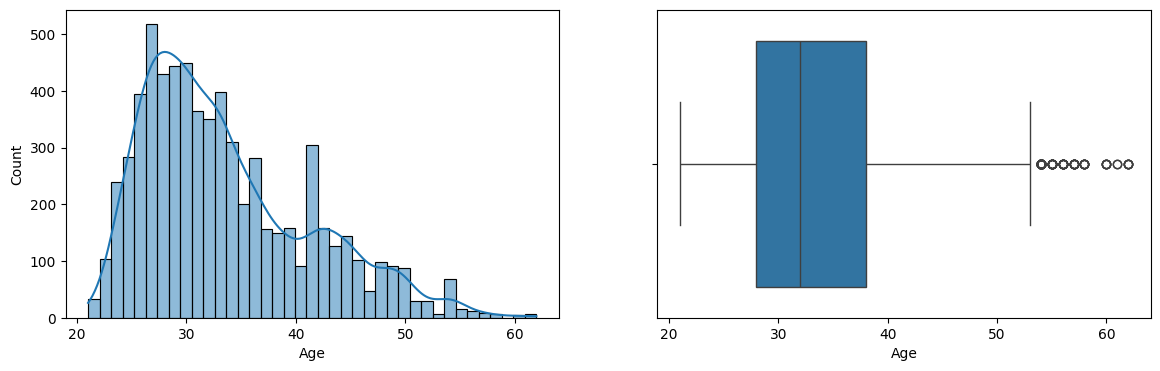

In [54]:
fig = plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(df['Age'], kde=True)

plt.subplot(122)
sns.boxplot(x=df['Age'])


<Axes: xlabel='Years of Experience'>

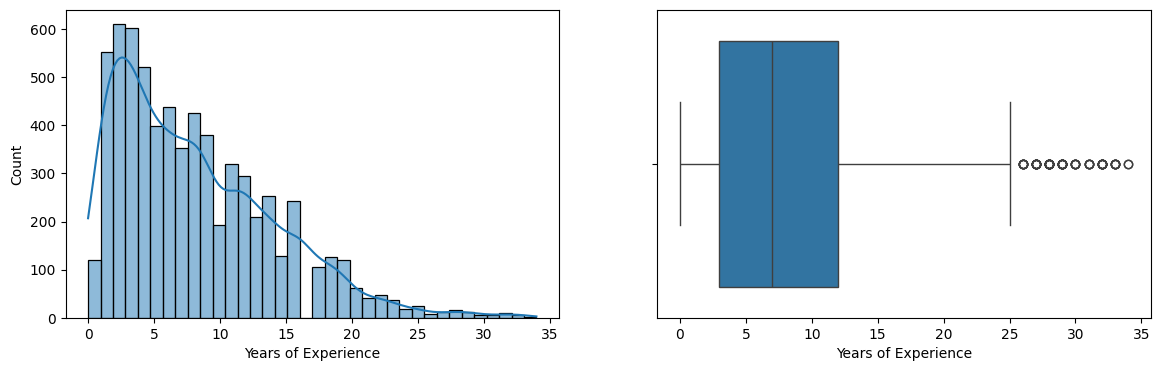

In [55]:
fig = plt.figure(figsize=(14,4))

plt.subplot(121)
sns.histplot(df['Years of Experience'], kde=True)

plt.subplot(122)
sns.boxplot(x=df['Years of Experience'])

## Handling Outlier in Age column

In [56]:
# Finding Quantiles
age_Q1 = df['Age'].quantile(0.25)
age_Q3 = df['Age'].quantile(0.75)

In [57]:
print(age_Q1)
print(age_Q3)

28.0
38.0


In [58]:
# Finding IQR
iqr = age_Q3 - age_Q1

In [59]:
iqr

np.float64(10.0)

In [60]:
# Finding UL & LL
age_UL = age_Q3 + 1.5*iqr
age_LL = age_Q1 - 1.5*iqr

print('age_UL:', age_UL)
print('age_LL:', age_LL)

age_UL: 53.0
age_LL: 13.0


## Finding Outlier 


In [61]:
df.shape

(6704, 6)

In [62]:
df[df['Age'] > age_UL]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
1211,61.0,Male,PhD,Software Engineer Manager,20.0,200000.0
1223,57.0,Male,PhD,Software Engineer Manager,18.0,195000.0
1225,62.0,Male,PhD,Software Engineer Manager,19.0,200000.0
1236,62.0,Male,PhD,Software Engineer Manager,20.0,200000.0
1240,55.0,Male,PhD,Software Engineer Manager,17.0,190000.0
...,...,...,...,...,...,...
3058,54.0,Male,Master's Degree,Senior Software Engineer,32.0,195270.0
3067,54.0,Male,Bachelor's Degree,Full Stack Engineer,25.0,179756.0
3084,54.0,Female,PhD,Software Engineer Manager,32.0,191510.0
3104,54.0,Male,PhD,Software Engineer Manager,30.0,184660.0


In [63]:
df[df['Age'] < age_LL]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary


## Trimming of Age column


In [64]:
new_df = df[df['Age'] < age_UL]

In [65]:
new_df.shape

(6572, 6)

<Axes: xlabel='Age'>

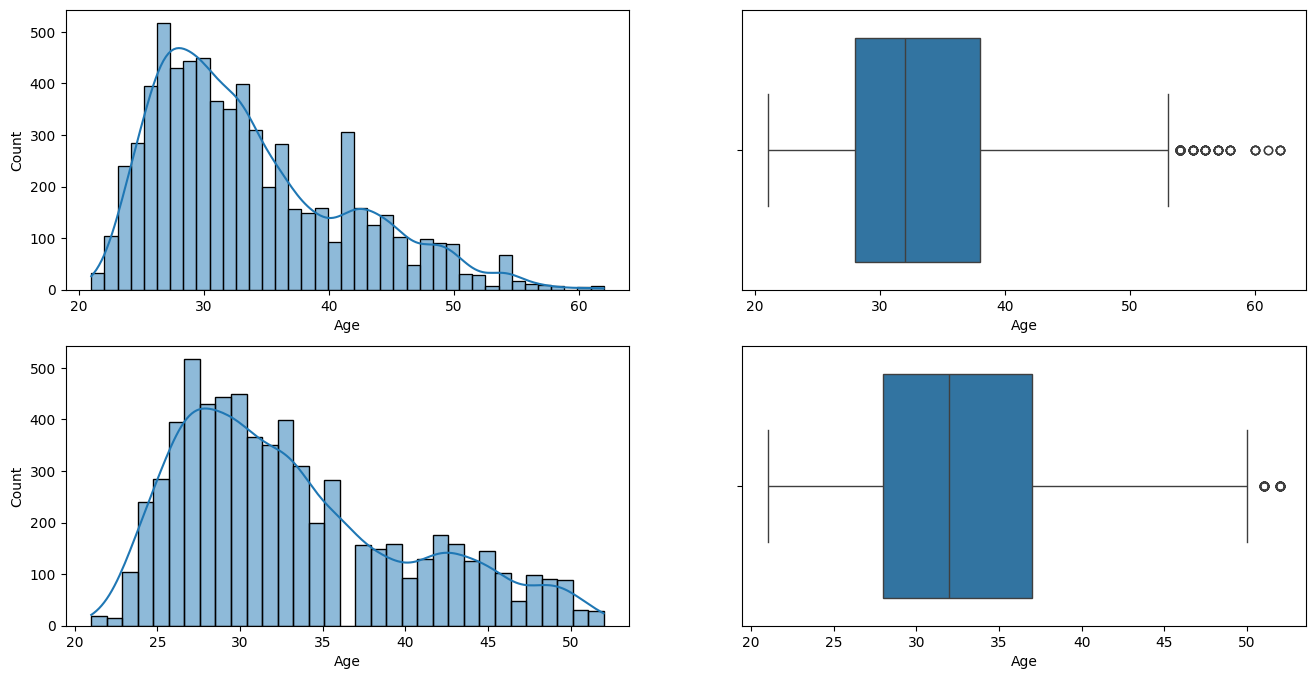

In [66]:
#Comparing

fig = plt.figure(figsize=(16,8))

plt.subplot(2,2,1)
sns.histplot(df['Age'], kde='True')

plt.subplot(2,2,2)
sns.boxplot(x=df['Age'])

plt.subplot(2,2,3)
sns.histplot(new_df['Age'], kde=True)

plt.subplot(2,2,4)
sns.boxplot(x=new_df['Age'])

## Capping of Age column

In [68]:
new_df_cap = df.copy()

new_df_cap['Age'] = np.where(
    new_df_cap['Age'] > age_UL,
    age_UL,
    np.where(
        new_df_cap['Age'] < age_LL,
        age_LL,
        new_df_cap['Age']
    )
)

In [69]:
new_df_cap.shape

(6704, 6)

<Axes: xlabel='Age'>

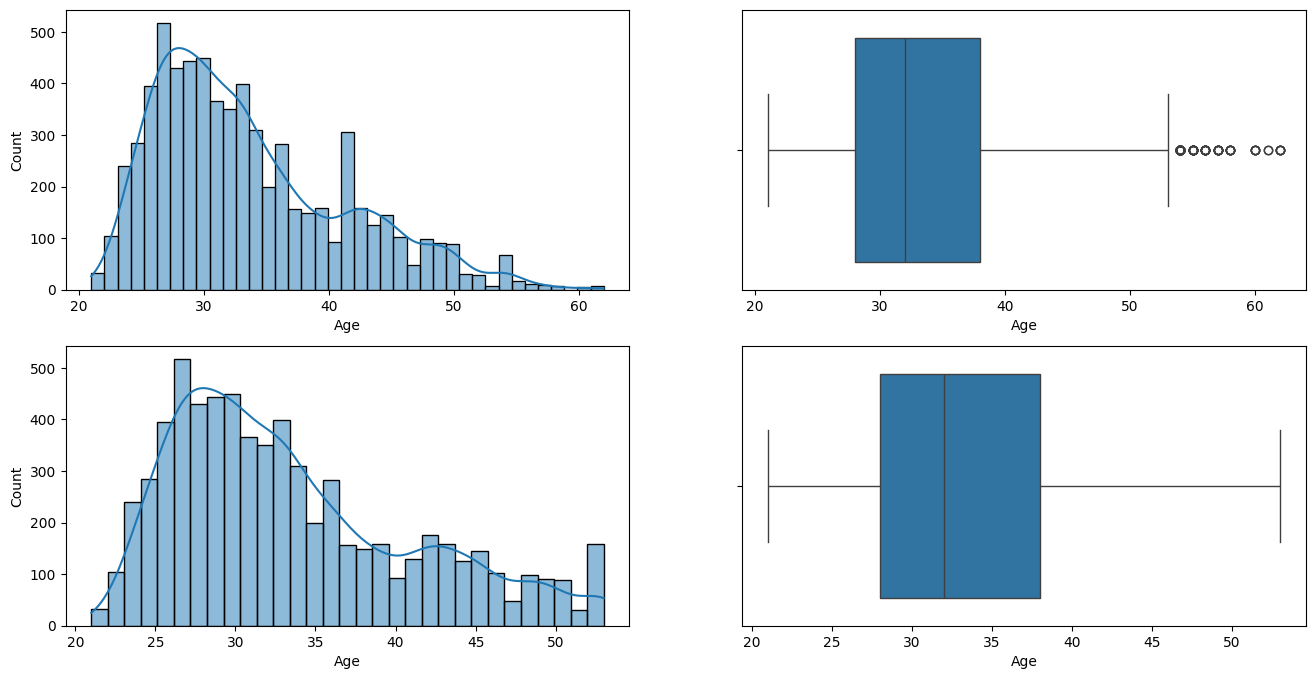

In [70]:
#Comparing

fig = plt.figure(figsize=(16,8))

plt.subplot(2,2,1)
sns.histplot(df['Age'], kde='True')

plt.subplot(2,2,2)
sns.boxplot(x=df['Age'])

plt.subplot(2,2,3)
sns.histplot(new_df_cap['Age'], kde=True)

plt.subplot(2,2,4)
sns.boxplot(x=new_df_cap['Age'])